In [ ]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving plant_dataset.zip.zip to plant_dataset.zip (1).zip


In [ ]:

import zipfile
from pathlib import Path

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/plant_data")

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [ ]:

base = Path("/content/plant_data")

TRAIN_DIR = next(base.rglob("train"))
TEST_DIR = next(base.rglob("test"))

print("Training folder:", TRAIN_DIR)
print("Testing folder:", TEST_DIR)

print("\nPlant disease classes:")
print([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])


Training folder: /content/plant_data/dataset/train
Testing folder: /content/plant_data/dataset/test

Plant disease classes:
['Tomato_Late_Blight', 'Healthy', 'Tomato_Early_Blight']


In [ ]:

def extract_features(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    image = cv2.resize(image, (128, 128))
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    features = []

    # 48 colour histogram features
    for channel, value_range in [
        (0, [0, 180]),
        (1, [0, 256]),
        (2, [0, 256])
    ]:
        hist = cv2.calcHist(
            [hsv], [channel], None, [16], value_range
        )
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)

    # 6 colour statistics
    image = image.astype(np.float32) / 255.0

    for channel in range(3):
        features.append(np.mean(image[:, :, channel]))
        features.append(np.std(image[:, :, channel]))

    # 2 edge statistics
    gray = cv2.cvtColor(
        (image * 255).astype(np.uint8),
        cv2.COLOR_BGR2GRAY
    )

    sx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    magnitude = np.sqrt(sx**2 + sy**2)

    features.append(np.mean(magnitude))
    features.append(np.std(magnitude))

    return np.asarray(features, dtype=np.float32)

print("Feature extraction ready!")


Feature extraction ready!


In [ ]:

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def load_dataset(folder):
    X = []
    y = []

    classes = sorted(
        p.name for p in folder.iterdir() if p.is_dir()
    )

    for class_name in classes:
        print("Loading:", class_name)
        class_folder = folder / class_name

        for image_path in class_folder.rglob("*"):
            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            features = extract_features(image_path)

            if features is not None:
                X.append(features)
                y.append(class_name)

    return np.array(X), np.array(y), classes


X_train, y_train, train_classes = load_dataset(TRAIN_DIR)
X_test, y_test, test_classes = load_dataset(TEST_DIR)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Classes:", train_classes)


Loading: Healthy
Loading: Tomato_Early_Blight
Loading: Tomato_Late_Blight
Loading: Healthy
Loading: Tomato_Early_Blight
Loading: Tomato_Late_Blight

Training shape: (3599, 56)
Testing shape: (901, 56)
Classes: ['Healthy', 'Tomato_Early_Blight', 'Tomato_Late_Blight']


In [ ]:

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    )
)

knn.fit(X_train, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [ ]:

y_pred = knn.predict(X_test)

print("Plant Disease Prediction Results")
print("-" * 45)

for i in range(min(20, len(y_test))):
    print(
        f"Actual: {y_test[i]} | "
        f"Predicted: {y_pred[i]} | "
        f"{'Correct' if y_test[i] == y_pred[i] else 'Wrong'}"
    )


Plant Disease Prediction Results
---------------------------------------------
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted: Healthy | Correct
Actual: Healthy | Predicted:

In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=train_classes,
    target_names=train_classes,
    zero_division=0
))


Accuracy: 94.78 %

Classification Report:
                     precision    recall  f1-score   support

            Healthy       0.97      1.00      0.99       319
Tomato_Early_Blight       0.89      0.93      0.90       200
 Tomato_Late_Blight       0.96      0.92      0.94       382

           accuracy                           0.95       901
          macro avg       0.94      0.95      0.94       901
       weighted avg       0.95      0.95      0.95       901



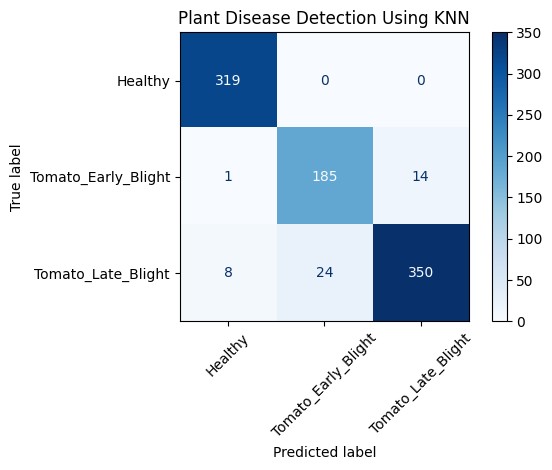

In [ ]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=train_classes,
    display_labels=train_classes,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Plant Disease Detection Using KNN")
plt.tight_layout()
plt.show()
